In [2]:
import pandas as pd
import numpy as np
dataset_enhanced = pd.read_csv('data/oropharynx_data_clin_trial.csv', header = [0,1,2], index_col = 0)

# Model fitting

In [3]:
import lymph
import emcee

graph_dict = {
    ('tumor', 'T')  : ['I','II', 'III', 'IV', 'V','VII'], 
    ('lnl'  , 'I')  : ['II'],
    ('lnl'  , 'II') : ['III'], 
    ('lnl'  , 'III'): ['IV'],
    ('lnl'  , 'IV') : ['V'],
    ('lnl'  , 'V')  : [],
    ('lnl'  , 'VII'): []
}
model = lymph.models.HPVUnilateral.binary(graph_dict=graph_dict, use_growth_mod = False)
model.set_modality("max_llh", spec = 1, sens = 1)
model.load_patient_data(dataset_enhanced)


/home/yoel/Documents/lymph_2026_evaluations/.venv/lib/python3.12/site-packages/lymph/models/unilateral.py:543: DataWarning: Modality enbloc_dissected does not contain involvement data for LNL I. Assuming unknown.
  warnings.warn(
/home/yoel/Documents/lymph_2026_evaluations/.venv/lib/python3.12/site-packages/lymph/models/unilateral.py:543: DataWarning: Modality enbloc_dissected does not contain involvement data for LNL II. Assuming unknown.
  warnings.warn(
/home/yoel/Documents/lymph_2026_evaluations/.venv/lib/python3.12/site-packages/lymph/models/unilateral.py:543: DataWarning: Modality enbloc_dissected does not contain involvement data for LNL V. Assuming unknown.
  warnings.warn(
/home/yoel/Documents/lymph_2026_evaluations/.venv/lib/python3.12/site-packages/lymph/models/unilateral.py:543: DataWarning: Modality enbloc_dissected does not contain involvement data for LNL VII. Assuming unknown.
  warnings.warn(
/home/yoel/Documents/lymph_2026_evaluations/.venv/lib/python3.12/site-package

In [5]:
len(model.hpv.patient_data['tumor'])

380

In [8]:
from scipy.special import factorial

def binom_pmf(k: np.ndarray, n: int, p: float):
    """Binomial PMF"""
    if p > 1. or p < 0.:
        # This value error is important to enable seamless sampling!
        raise ValueError("Binomial prob must be btw. 0 and 1")
    q = (1. - p)
    binom_coeff = factorial(n) / (factorial(k) * factorial(n - k))
    return binom_coeff * p**k * q**(n - k)

def late_binomial(support: np.ndarray, p: float = 0.5) -> np.ndarray:
    """Parametrized binomial distribution."""
    return binom_pmf(k=support, n=support[-1], p=p)

model.set_distribution("early", binom_pmf(np.arange(11), 10, 0.3))
model.set_distribution("late", late_binomial)

In [12]:
backend = emcee.backends.HDFBackend(filename = "full_ipsi_HPV")

In [13]:
model.get_params()

{'hpv_TtoI_spread': 0.5,
 'hpv_TtoII_spread': 0.5,
 'hpv_TtoIII_spread': 0.5,
 'hpv_TtoIV_spread': 0.5,
 'hpv_TtoV_spread': 0.5,
 'hpv_TtoVII_spread': 0.5,
 'nohpv_TtoII_spread': 0.5,
 'ItoII_spread': 0.5,
 'IItoIII_spread': 0.5,
 'IIItoIV_spread': 0.5,
 'IVtoV_spread': 0.5,
 'late_p': 0.5}

In [14]:
from multiprocess import Pool
# plus one dimension for the late T-stage's time parameter
params = ['TtoI_spread', 'TtoII_spread', 'TtoIII_spread', 'TtoIV_spread', 'TtoV_spread', 'TtoVII_spread', 'nohpv_TtoII_spread', 'ItoII_spread', 'IItoIII_spread', 'IIItoIV_spread', 'IVtoV_spread', 'late_p']
ndim = len(params)

# number of concurrent walkers that sample the space
nwalkers = 10 * ndim
# define the log-likelihood
def log_prob_fn(theta): 
    return model.likelihood(given_params=theta,log=True)

max_steps = 100
# backend.reset(nwalkers, ndim)

# initialize the sampler with some random samples
starting_points = np.random.uniform(size=(nwalkers,ndim))

# use Pool() from multiprocessing for parallelisation
with Pool() as pool:
    original_sampler = emcee.EnsembleSampler(
        nwalkers, ndim, log_prob_fn,
        pool=pool, backend=backend, parameter_names = params
    )
    original_sampler.run_mcmc(None,nsteps=max_steps, progress=True)


100%|██████████| 100/100 [00:20<00:00,  4.88it/s]


burn-in: 621
thin: 49
flat chain shape: (37800, 12)
(16100, 120, 12)


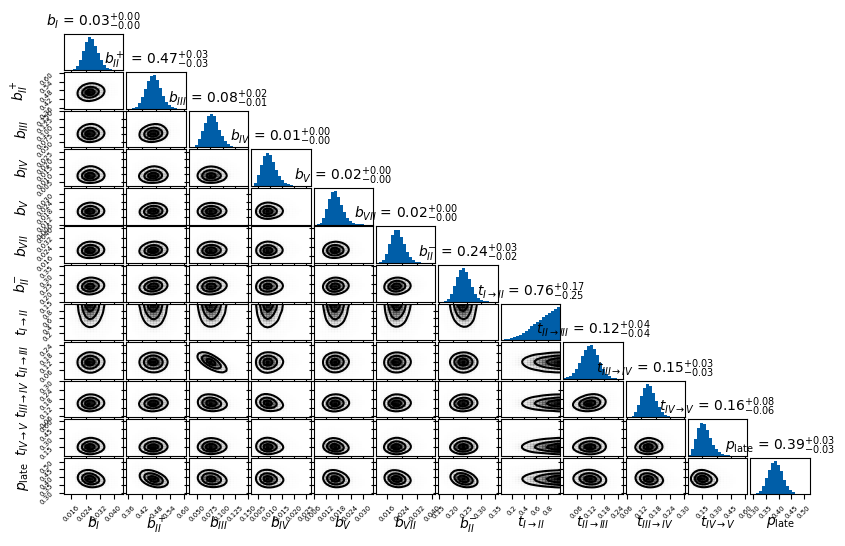

In [15]:
tau = backend.get_autocorr_time()
# tau = 1200
burnin = int(2 * np.max(tau))
thin = int(0.5 * np.min(tau))
samples = backend.get_chain(discard=burnin, flat=True, thin=thin)
print("burn-in: {0}".format(burnin))
print("thin: {0}".format(thin))
print("flat chain shape: {0}".format(samples.shape))
print(backend.get_chain().shape)


import matplotlib.pyplot as plt
import matplotlib.gridspec as gs
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.colors import ListedColormap
from cycler import cycler
import corner

# USZ colors
usz_blue = '#005ea8'
usz_green = '#00afa5'
usz_red = '#ae0060'
usz_orange = '#f17900'
usz_gray = '#c5d5db'

# colormaps
white_to_blue  = LinearSegmentedColormap.from_list("white_to_blue", 
                                                   ["#ffffff", usz_blue], 
                                                   N=256)
white_to_green = LinearSegmentedColormap.from_list("white_to_green", 
                                                   ["#ffffff", usz_green], 
                                                   N=256)
green_to_red   = LinearSegmentedColormap.from_list("green_to_red", 
                                                   [usz_green, usz_red], 
                                                   N=256)

h = usz_gray.lstrip('#')
gray_rgba = tuple(int(h[i:i+2], 16) / 255. for i in (0, 2, 4)) + (1.0,)
tmp = LinearSegmentedColormap.from_list("tmp", [usz_green, usz_red], N=128)
tmp = tmp(np.linspace(0., 1., 128))
tmp = np.vstack([np.array([gray_rgba]*128), tmp])
halfGray_halfGreenToRed = ListedColormap(tmp)


def set_size(width="single", unit="cm", ratio="golden"):
    if width == "single":
        width = 10
    elif width == "full":
        width = 20
    else:
        try:
            width = width
        except:
            width = 10
            
    if unit == "cm":
        width = width / 2.54
        
    if ratio == "golden":
        ratio = 1.618
    else:
        ratio = ratio
    
    try:
        height = width / ratio
    except:
        height = width / 1.618
        
    return (width, height)



labels = [
    r"$b_I$",
    r"$b_{II}^+$",
    r"$b_{III}$",
    r"$b_{IV}$",
    r"$b_V$",
    r"$b_{VII}$",
    r"$b_{II}^{-}$",
    r"$t_{I \to II}$",
    r"$t_{II \to III}$",
    r"$t_{III \to IV}$",
    r"$t_{IV \to V}$",
    r"$p_{\text{late}}$",
]

fig = plt.figure(figsize=set_size(width="full", ratio='golden'))
# using the corner plot package

corner.corner(samples, labels=labels, smooth=True, fig=fig, 
              hist_kwargs={'histtype': 'stepfilled', 'color': usz_blue}, 
              **{'plot_datapoints': False, 'no_fill_contours': True, 
                 "density_cmap": white_to_blue.reversed(), 
                 "contour_kwargs": {"colors": "k"}, 
                 "levels": np.array([0.2, 0.5, 0.8])}, 
              show_titles=True, title_kwargs={"fontsize": 10},labelpad =0.25);

axes = fig.get_axes()
for ax in axes:
    ax.grid(False)
    ax.tick_params(axis='both', labelsize=5)

In [16]:
samples_mean = np.mean(samples,axis = 0)
params = ['TtoI_spread', 'TtoII_spread', 'TtoIII_spread', 'TtoIV_spread', 'TtoV_spread', 'TtoVII_spread', 'nohpv_TtoII_spread', 'ItoII_spread', 'IItoIII_spread', 'IIItoIV_spread', 'IVtoV_spread', 'late_p']

model.set_params(**dict(zip(params, samples_mean)))

()

In [18]:
model.set_modality("clinical", spec = 1, sens = 0.81)


In [19]:
involvement = {
    'II':True
}
diagnosis = {'clinical':{
    'I':False,
    'II':False,
    'III':False,
    'IV':False,
    'V':False,
    'VII':False
}}

model.risk(involvement = involvement, given_diagnosis = diagnosis, hpv = True, t_stage = 'early')*100

np.float64(32.93023494419796)

In [20]:
import lydata as ly
dataset_reduced = dataset_enhanced.loc[dataset_enhanced.ly.hpv.notna()]
hpv_pos = dataset_reduced.loc[dataset_reduced.ly.hpv]
hpv_neg = dataset_reduced.loc[~dataset_reduced.ly.hpv.astype(bool)]
hpv_pos_early = hpv_pos.loc[hpv_pos['tumor','core','t_stage'] < 3]
hpv_pos_late = hpv_pos.loc[hpv_pos['tumor','core','t_stage'] > 2]
hpv_neg_early = hpv_neg.loc[hpv_neg['tumor','core','t_stage'] < 3]
hpv_neg_late = hpv_neg.loc[hpv_neg['tumor','core','t_stage'] > 2]

In [21]:
hpv_pos_early['max_llh']['ipsi']['II'].sum()/len(hpv_pos_early)

np.float64(0.8008474576271186)

In [22]:
hpv_pos_late['max_llh']['ipsi']['II'].sum()/len(hpv_pos_late)

np.float64(0.8402777777777778)

In [23]:
hpv_neg_early['max_llh']['ipsi']['II'].sum()/len(hpv_neg_early)

np.float64(0.4909090909090909)

## Plots

In [24]:
len(samples)/100

378.0

In [25]:
def risk_sampled(samples, model, t_stage, hpv = False, involvement = None, given_diagnoses = None, thin = 10):
    params = ['TtoI_spread', 'TtoII_spread', 'TtoIII_spread', 'TtoIV_spread', 'TtoV_spread', 'TtoVII_spread', 'nohpv_TtoII_spread', 'ItoII_spread', 'IItoIII_spread', 'IIItoIV_spread', 'IVtoV_spread', 'late_p']
    if involvement == None:
        sampled_risks = np.zeros(shape=(len(samples[::thin]),len(model.graph.state_list)), dtype=float)
    else:
        sampled_risks = np.zeros(shape=(len(samples[::thin])), dtype=float)
    for i, sample in enumerate(np.random.permutation(samples[::thin])):
        model.set_params(**dict(zip(params, sample)))
        if involvement == None:
            sampled_risks[i] = model.posterior_state_dist(t_stage = t_stage, given_diagnosis = given_diagnoses) 
        else:
            sampled_risks[i] = model.risk(hpv = hpv, t_stage = t_stage, given_diagnosis = given_diagnoses, involvement = involvement) 
    mean_risk = sampled_risks.mean(axis = 0)
    return sampled_risks, mean_risk

In [26]:
involvement_II = {'II':True}
involvement_III = {'III':True}
involvement_IV = {'IV':True}
thin = 100
risks_II_early_nohpv, mean_risk_II_early_nohpv = risk_sampled(samples = samples, model = model, hpv = False, t_stage = 'early', involvement = involvement_II, thin = thin) 
risks_II_late_nohpv, mean_risk_II_late_nohpv = risk_sampled(samples = samples, model = model, hpv = False, t_stage = 'late', involvement = involvement_II, thin = thin) 
risks_II_early_hpv, mean_risk_II_early_hpv = risk_sampled(samples = samples, model = model, hpv = True, t_stage = 'early', involvement = involvement_II, thin = thin) 
risks_II_late_hpv, mean_risk_late_hpv = risk_sampled(samples = samples, model = model, hpv = True, t_stage = 'late', involvement = involvement_II, thin = thin) 

risks_III_early_nohpv, mean_risk_III_early_nohpv = risk_sampled(samples = samples, model = model, hpv = False, t_stage = 'early', involvement = involvement_III, thin = thin) 
risks_III_late_nohpv, mean_risk_III_late_nohpv = risk_sampled(samples = samples, model = model, hpv = False, t_stage = 'late', involvement = involvement_III, thin = thin) 
risks_III_early_hpv, mean_risk_III_early_hpv = risk_sampled(samples = samples, model = model, hpv = True, t_stage = 'early', involvement = involvement_III, thin = thin) 
risks_III_late_hpv, mean_risk_III_late_hpv = risk_sampled(samples = samples, model = model, hpv = True, t_stage = 'late', involvement = involvement_III, thin = thin) 

risks_IV_early_nohpv, mean_risk_IV_early_nohpv = risk_sampled(samples = samples, model = model, hpv = False, t_stage = 'early', involvement = involvement_IV, thin = thin) 
risks_IV_late_nohpv, mean_risk_IV_late_nohpv = risk_sampled(samples = samples, model = model, hpv = False, t_stage = 'late', involvement = involvement_IV, thin = thin) 
risks_IV_early_hpv, mean_risk_IV_early_hpv = risk_sampled(samples = samples, model = model, hpv = True, t_stage = 'early', involvement = involvement_IV, thin = thin) 
risks_IV_late_hpv, mean_risk_IV_late_hpv = risk_sampled(samples = samples, model = model, hpv = True, t_stage = 'late', involvement = involvement_IV, thin = thin) 



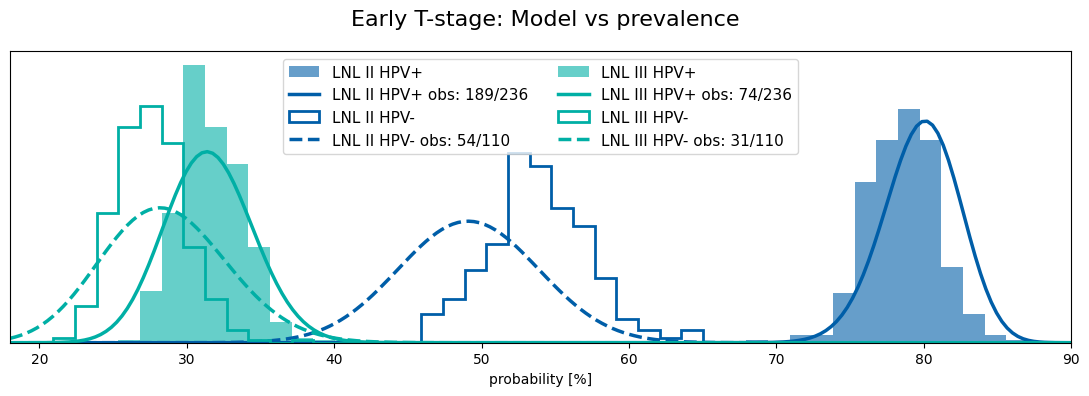

In [ ]:
import scipy as sp

COLORS = {"green": '#00afa5',
    "blue": '#005ea8',
    "orange": '#f17900',
    "red": '#ae0060',
    "gray": '#c5d5db',
}

# Prepare risk distributions for plotting (convert to percentages)
risk_distributions = {
    'II_early_hpv': risks_II_early_hpv * 100,
    'II_early_nohpv': risks_II_early_nohpv * 100,
    'III_early_hpv': risks_III_early_hpv * 100,
    'III_early_nohpv': risks_III_early_nohpv * 100,
}

# Get observed prevalences from data
prevalence_data = {
    'II_early_hpv': (hpv_pos_early['max_llh']['ipsi']['II'].sum(), len(hpv_pos_early)),
    'II_early_nohpv': (hpv_neg_early['max_llh']['ipsi']['II'].sum(), len(hpv_neg_early)),
    'III_early_hpv': (hpv_pos_early['max_llh']['ipsi']['III'].sum(), len(hpv_pos_early)),
    'III_early_nohpv': (hpv_neg_early['max_llh']['ipsi']['III'].sum(), len(hpv_neg_early)),
}

labels_plot = {
    'II_early_hpv': 'LNL II HPV+',
    'II_early_nohpv': 'LNL II HPV-',
    'III_early_hpv': 'LNL III HPV+',
    'III_early_nohpv': 'LNL III HPV-',
}

# Color mapping: same color for same LNL
color_map = {
    'II_early_hpv': COLORS['blue'],
    'II_early_nohpv': COLORS['blue'],
    'III_early_hpv': COLORS['green'],
    'III_early_nohpv': COLORS['green'],
}

# Style mapping: HPV+ filled/solid, HPV- outline/dashed
hist_style = {
    'II_early_hpv': {'histtype': 'stepfilled', 'alpha': 0.6},
    'II_early_nohpv': {'histtype': 'step', 'alpha': 1.0},
    'III_early_hpv': {'histtype': 'stepfilled', 'alpha': 0.6},
    'III_early_nohpv': {'histtype': 'step', 'alpha': 1.0},
}

line_style = {
    'II_early_hpv': '-',
    'II_early_nohpv': '--',
    'III_early_hpv': '-',
    'III_early_nohpv': '--',
}

# Plot settings
min_value = 18
max_value = 90
base_hist_kwargs = {
    "bins": np.linspace(min_value, max_value, 50),
    "density": True,
    "linewidth": 2.,
}

fig, ax = plt.subplots(figsize=(11, 4))
x = np.linspace(min_value, max_value, 200)

# Plot each distribution
for key in ['II_early_hpv', 'II_early_nohpv', 'III_early_hpv', 'III_early_nohpv']:
    vals = risk_distributions[key]
    label = labels_plot[key]
    a, n = prevalence_data[key]
    color = color_map[key]
    
    # Histogram
    ax.hist(
        vals,
        label=label,
        color=color,
        **base_hist_kwargs,
        **hist_style[key]
    )
    
    # Beta posterior
    if not np.isnan(a) and n > 0:
        post = sp.stats.beta.pdf(x / 100., a+1, n-a+1) / 100.
        ax.plot(x, post, 
                label=f"{label} obs: {int(a)}/{int(n)}", 
                color=color,
                linestyle=line_style[key],
                linewidth=2.5)

ax.legend(fontsize=11, ncol=2)
ax.set_yticks([])
ax.set_xlabel("probability [%]")
ax.set_xlim(min_value,max_value)
plt.suptitle('Early T-stage: Model vs prevalence', fontsize=16)
plt.tight_layout()
plt.savefig('figures/HPV_early_prevalence.png', dpi=300)

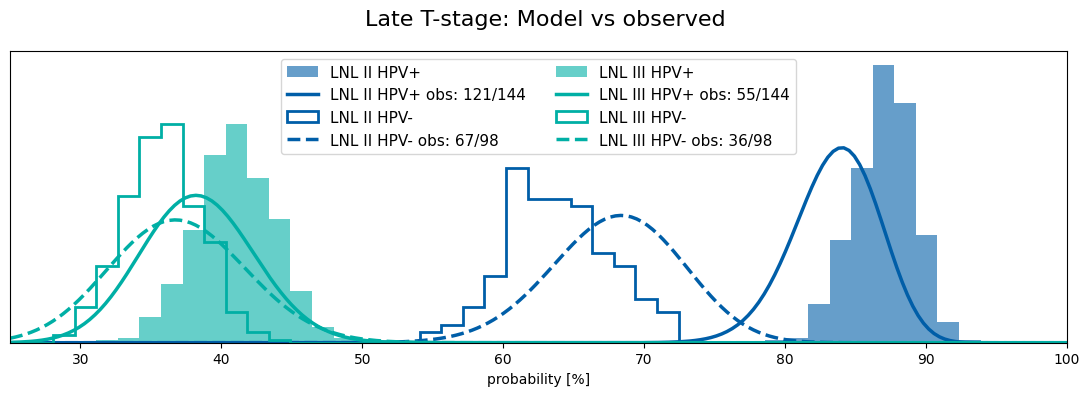

In [ ]:
import scipy as sp

COLORS = {"green": '#00afa5',
    "blue": '#005ea8',
    "orange": '#f17900',
    "red": '#ae0060',
    "gray": '#c5d5db',
}

# Prepare risk distributions for plotting (convert to percentages)
risk_distributions = {
    'II_late_hpv': risks_II_late_hpv * 100,
    'II_late_nohpv': risks_II_late_nohpv * 100,
    'III_late_hpv': risks_III_late_hpv * 100,
    'III_late_nohpv': risks_III_late_nohpv * 100,
}

# Get observed prevalences from data
prevalence_data = {
    'II_late_hpv': (hpv_pos_late['max_llh']['ipsi']['II'].sum(), len(hpv_pos_late)),
    'II_late_nohpv': (hpv_neg_late['max_llh']['ipsi']['II'].sum(), len(hpv_neg_late)),
    'III_late_hpv': (hpv_pos_late['max_llh']['ipsi']['III'].sum(), len(hpv_pos_late)),
    'III_late_nohpv': (hpv_neg_late['max_llh']['ipsi']['III'].sum(), len(hpv_neg_late)),
}

labels_plot = {
    'II_late_hpv': 'LNL II HPV+',
    'II_late_nohpv': 'LNL II HPV-',
    'III_late_hpv': 'LNL III HPV+',
    'III_late_nohpv': 'LNL III HPV-',
}

# Color mapping: same color for same LNL
color_map = {
    'II_late_hpv': COLORS['blue'],
    'II_late_nohpv': COLORS['blue'],
    'III_late_hpv': COLORS['green'],
    'III_late_nohpv': COLORS['green'],
}

# Style mapping: HPV+ filled/solid, HPV- outline/dashed
hist_style = {
    'II_late_hpv': {'histtype': 'stepfilled', 'alpha': 0.6},
    'II_late_nohpv': {'histtype': 'step', 'alpha': 1.0},
    'III_late_hpv': {'histtype': 'stepfilled', 'alpha': 0.6},
    'III_late_nohpv': {'histtype': 'step', 'alpha': 1.0},
}

line_style = {
    'II_late_hpv': '-',
    'II_late_nohpv': '--',
    'III_late_hpv': '-',
    'III_late_nohpv': '--',
}

# Plot settings
min_value = 25
max_value = 100
base_hist_kwargs = {
    "bins": np.linspace(min_value, max_value, 50),
    "density": True,
    "linewidth": 2.,
}

fig, ax = plt.subplots(figsize=(11, 4))
x = np.linspace(min_value, max_value, 200)

# Plot each distribution
for key in ['II_late_hpv', 'II_late_nohpv', 'III_late_hpv', 'III_late_nohpv']:
    vals = risk_distributions[key]
    label = labels_plot[key]
    a, n = prevalence_data[key]
    color = color_map[key]
    
    # Histogram
    ax.hist(
        vals,
        label=label,
        color=color,
        **base_hist_kwargs,
        **hist_style[key]
    )
    
    # Beta posterior
    if not np.isnan(a) and n > 0:
        post = sp.stats.beta.pdf(x / 100., a+1, n-a+1) / 100.
        ax.plot(x, post, 
                label=f"{label} obs: {int(a)}/{int(n)}", 
                color=color,
                linestyle=line_style[key],
                linewidth=2.5)

ax.legend(fontsize=11, ncol=2)
ax.set_yticks([])
ax.set_xlabel("probability [%]")
ax.set_xlim(min_value,max_value)

plt.suptitle('Late T-stage: Model vs observed', fontsize=16)
plt.tight_layout()
plt.savefig('figures/HPV_late_prevalence.png', dpi=300)

In [29]:
involvement_II_III = {'II':True,
                      'III':True}
involvement_notII_III = {'II':False,
                      'III':True}

thin = 100
risks_II_III_early_nohpv, mean_risk_II_III_early_nohpv = risk_sampled(samples=samples, model=model, hpv=False, t_stage='early', involvement=involvement_II_III, thin=thin)
risks_II_III_late_nohpv, mean_risk_II_III_late_nohpv = risk_sampled(samples=samples, model=model, hpv=False, t_stage='late', involvement=involvement_II_III, thin=thin)
risks_II_III_early_hpv, mean_risk_II_III_early_hpv = risk_sampled(samples=samples, model=model, hpv=True, t_stage='early', involvement=involvement_II_III, thin=thin)
risks_II_III_late_hpv, mean_risk_II_III_late_hpv = risk_sampled(samples=samples, model=model, hpv=True, t_stage='late', involvement=involvement_II_III, thin=thin)

risks_notII_III_early_nohpv, mean_risk_notII_III_early_nohpv = risk_sampled(samples=samples, model=model, hpv=False, t_stage='early', involvement=involvement_notII_III, thin=thin)
risks_notII_III_late_nohpv, mean_risk_notII_III_late_nohpv = risk_sampled(samples=samples, model=model, hpv=False, t_stage='late', involvement=involvement_notII_III, thin=thin)
risks_notII_III_early_hpv, mean_risk_notII_III_early_hpv = risk_sampled(samples=samples, model=model, hpv=True, t_stage='early', involvement=involvement_notII_III, thin=thin)
risks_notII_III_late_hpv, mean_risk_notII_III_late_hpv = risk_sampled(samples=samples, model=model, hpv=True, t_stage='late', involvement=involvement_notII_III, thin=thin)


In [30]:
mean_risk_II_III_late_nohpv

np.float64(0.27635806562140336)

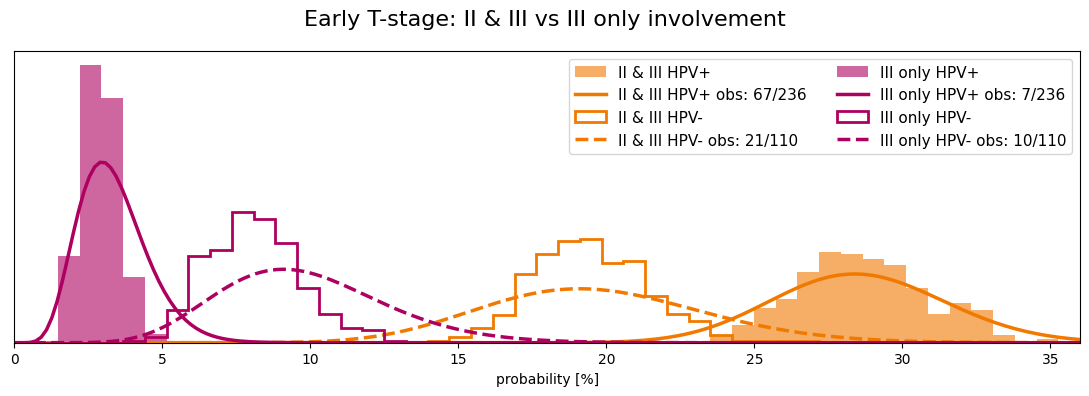

In [ ]:
import scipy as sp

COLORS = {"green": '#00afa5',
    "blue": '#005ea8',
    "orange": '#f17900',
    "red": '#ae0060',
    "gray": '#c5d5db',
}

risk_distributions = {
    'II_III_early_hpv': risks_II_III_early_hpv * 100,
    'II_III_early_nohpv': risks_II_III_early_nohpv * 100,
    'notII_III_early_hpv': risks_notII_III_early_hpv * 100,
    'notII_III_early_nohpv': risks_notII_III_early_nohpv * 100,
}

# For prevalence: patients with II+III both positive, and patients with III positive but II negative
dataset_II_III_hpv = hpv_pos_early.loc[(hpv_pos_early['max_llh']['ipsi']['II'] == True) & (hpv_pos_early['max_llh']['ipsi']['III'] == True)]
dataset_II_III_nohpv = hpv_neg_early.loc[(hpv_neg_early['max_llh']['ipsi']['II'] == True) & (hpv_neg_early['max_llh']['ipsi']['III'] == True)]
dataset_notII_III_hpv = hpv_pos_early.loc[(hpv_pos_early['max_llh']['ipsi']['II'] == False) & (hpv_pos_early['max_llh']['ipsi']['III'] == True)]
dataset_notII_III_nohpv = hpv_neg_early.loc[(hpv_neg_early['max_llh']['ipsi']['II'] == False) & (hpv_neg_early['max_llh']['ipsi']['III'] == True)]

prevalence_data = {
    'II_III_early_hpv': (len(dataset_II_III_hpv), len(hpv_pos_early)),
    'II_III_early_nohpv': (len(dataset_II_III_nohpv), len(hpv_neg_early)),
    'notII_III_early_hpv': (len(dataset_notII_III_hpv), len(hpv_pos_early)),
    'notII_III_early_nohpv': (len(dataset_notII_III_nohpv), len(hpv_neg_early)),
}

labels_plot = {
    'II_III_early_hpv': 'II & III HPV+',
    'II_III_early_nohpv': 'II & III HPV-',
    'notII_III_early_hpv': 'III only HPV+',
    'notII_III_early_nohpv': 'III only HPV-',
}

color_map = {
    'II_III_early_hpv': COLORS['orange'],
    'II_III_early_nohpv': COLORS['orange'],
    'notII_III_early_hpv': COLORS['red'],
    'notII_III_early_nohpv': COLORS['red'],
}

hist_style = {
    'II_III_early_hpv': {'histtype': 'stepfilled', 'alpha': 0.6},
    'II_III_early_nohpv': {'histtype': 'step', 'alpha': 1.0},
    'notII_III_early_hpv': {'histtype': 'stepfilled', 'alpha': 0.6},
    'notII_III_early_nohpv': {'histtype': 'step', 'alpha': 1.0},
}

line_style = {
    'II_III_early_hpv': '-',
    'II_III_early_nohpv': '--',
    'notII_III_early_hpv': '-',
    'notII_III_early_nohpv': '--',
}

min_value = 0
max_value = 36
base_hist_kwargs = {
    "bins": np.linspace(min_value, max_value, 50),
    "density": True,
    "linewidth": 2.,
}

fig, ax = plt.subplots(figsize=(11, 4))
x = np.linspace(min_value, max_value, 200)

for key in ['II_III_early_hpv', 'II_III_early_nohpv', 'notII_III_early_hpv', 'notII_III_early_nohpv']:
    vals = risk_distributions[key]
    label = labels_plot[key]
    a, n = prevalence_data[key]
    color = color_map[key]
    
    ax.hist(vals, label=label, color=color, **base_hist_kwargs, **hist_style[key])
    
    if not np.isnan(a) and n > 0:
        post = sp.stats.beta.pdf(x / 100., a+1, n-a+1) / 100.
        ax.plot(x, post, label=f"{label} obs: {int(a)}/{int(n)}", color=color, linestyle=line_style[key], linewidth=2.5)

ax.legend(fontsize=11, ncol=2)
ax.set_yticks([])
ax.set_xlabel("probability [%]")
ax.set_xlim(min_value,max_value)

plt.suptitle('Early T-stage: II & III vs III only involvement', fontsize=16)
plt.tight_layout()
plt.savefig('figures/HPV_early_II_III_patterns.png', dpi=300)

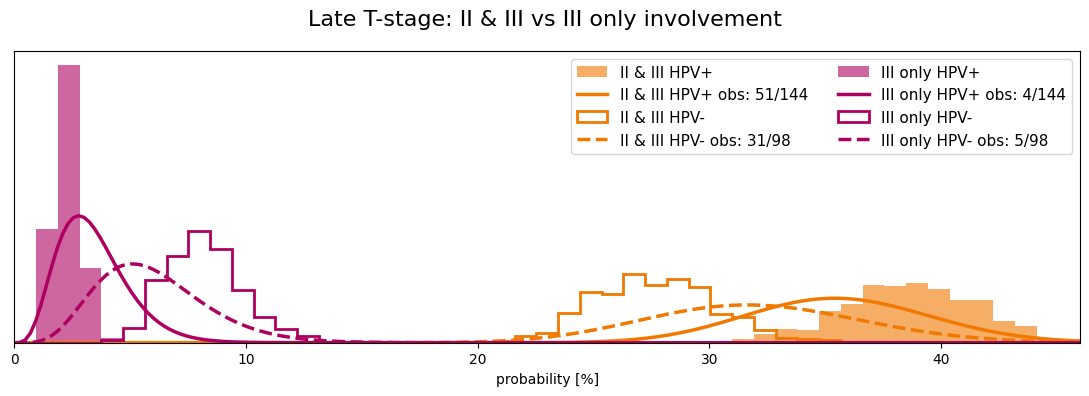

In [ ]:
import scipy as sp

COLORS = {"green": '#00afa5',
    "blue": '#005ea8',
    "orange": '#f17900',
    "red": '#ae0060',
    "gray": '#c5d5db',
}

risk_distributions = {
    'II_III_late_hpv': risks_II_III_late_hpv * 100,
    'II_III_late_nohpv': risks_II_III_late_nohpv * 100,
    'notII_III_late_hpv': risks_notII_III_late_hpv * 100,
    'notII_III_late_nohpv': risks_notII_III_late_nohpv * 100,
}

# For prevalence: patients with II+III both positive, and patients with III positive but II negative
dataset_II_III_hpv = hpv_pos_late.loc[(hpv_pos_late['max_llh']['ipsi']['II'] == True) & (hpv_pos_late['max_llh']['ipsi']['III'] == True)]
dataset_II_III_nohpv = hpv_neg_late.loc[(hpv_neg_late['max_llh']['ipsi']['II'] == True) & (hpv_neg_late['max_llh']['ipsi']['III'] == True)]
dataset_notII_III_hpv = hpv_pos_late.loc[(hpv_pos_late['max_llh']['ipsi']['II'] == False) & (hpv_pos_late['max_llh']['ipsi']['III'] == True)]
dataset_notII_III_nohpv = hpv_neg_late.loc[(hpv_neg_late['max_llh']['ipsi']['II'] == False) & (hpv_neg_late['max_llh']['ipsi']['III'] == True)]

prevalence_data = {
    'II_III_late_hpv': (len(dataset_II_III_hpv), len(hpv_pos_late)),
    'II_III_late_nohpv': (len(dataset_II_III_nohpv), len(hpv_neg_late)),
    'notII_III_late_hpv': (len(dataset_notII_III_hpv), len(hpv_pos_late)),
    'notII_III_late_nohpv': (len(dataset_notII_III_nohpv), len(hpv_neg_late)),
}

labels_plot = {
    'II_III_late_hpv': 'II & III HPV+',
    'II_III_late_nohpv': 'II & III HPV-',
    'notII_III_late_hpv': 'III only HPV+',
    'notII_III_late_nohpv': 'III only HPV-',
}

color_map = {
    'II_III_late_hpv': COLORS['orange'],
    'II_III_late_nohpv': COLORS['orange'],
    'notII_III_late_hpv': COLORS['red'],
    'notII_III_late_nohpv': COLORS['red'],
}

hist_style = {
    'II_III_late_hpv': {'histtype': 'stepfilled', 'alpha': 0.6},
    'II_III_late_nohpv': {'histtype': 'step', 'alpha': 1.0},
    'notII_III_late_hpv': {'histtype': 'stepfilled', 'alpha': 0.6},
    'notII_III_late_nohpv': {'histtype': 'step', 'alpha': 1.0},
}

line_style = {
    'II_III_late_hpv': '-',
    'II_III_late_nohpv': '--',
    'notII_III_late_hpv': '-',
    'notII_III_late_nohpv': '--',
}

min_value = 0
max_value = 46
base_hist_kwargs = {
    "bins": np.linspace(min_value, max_value, 50),
    "density": True,
    "linewidth": 2.,
}

fig, ax = plt.subplots(figsize=(11, 4))
x = np.linspace(min_value, max_value, 200)

for key in ['II_III_late_hpv', 'II_III_late_nohpv', 'notII_III_late_hpv', 'notII_III_late_nohpv']:
    vals = risk_distributions[key]
    label = labels_plot[key]
    a, n = prevalence_data[key]
    color = color_map[key]
    
    ax.hist(vals, label=label, color=color, **base_hist_kwargs, **hist_style[key])
    
    if not np.isnan(a) and n > 0:
        post = sp.stats.beta.pdf(x / 100., a+1, n-a+1) / 100.
        ax.plot(x, post, label=f"{label} obs: {int(a)}/{int(n)}", color=color, linestyle=line_style[key], linewidth=2.5)

ax.legend(fontsize=11, ncol=2)
ax.set_yticks([])
ax.set_xlabel("probability [%]")
ax.set_xlim(min_value,max_value)

plt.suptitle('Late T-stage: II & III vs III only involvement', fontsize=16)
plt.tight_layout()
plt.savefig('figures/HPV_late_II_III_patterns.png', dpi=300)